<a href="https://colab.research.google.com/github/robertbarcik/genai-in-python-tutorial/blob/main/9b_decision_models/9b_decision_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Models: When the Model Only Has to Choose

You may have seen the headlines this autumn: a model called **Jev** that "plays Doom" for a few dollars an hour, Microsoft's **Decision-1**, OpenAI's **Decisions API**. All of them are sold the same way: no text comes out, only a decision, and it comes back in a fraction of a second for a fraction of the price.

A fair first reaction: "isn't that just function calling with a smaller model?" It is not, and the difference is the whole lecture. Let's get there step by step: first the idea, then the API, then three small places in an app where it earns its keep, then the bill.

Background reading, if you are curious (none of it is required):

- Microsoft: [Introducing Microsoft-Decision-1, our model for fast decision-making](https://commandline.microsoft.com/microsoft-decision-1-model-foundry/) (October 2026)
- OpenAI: [Decisions API guide](https://developers.openai.com/api/docs/guides/decisions) and the [changelog entry of 6 October 2026](https://developers.openai.com/api/docs/changelog) that opened the public beta
- The Register on Jev: [TypeSafe AI debuts model for machines that plays Doom](https://www.theregister.com/a/5296711) (September 2026)
- A sceptical take worth reading after this notebook: Sean Goedecke, [Jev means structured output is interesting again](https://www.seangoedecke.com/jev-means-structured-output-is-interesting-again/)

## Three things a model can do for you

Think about what you have asked a model to do so far in this course. **Generate**: text in, text out. Every chat, every JSON object in the structured-outputs chapter, every function call. **Embed**: text in, a list of numbers out, the RAG chapter. Today we add a third. **Decide**: text in, one option from a list *you* wrote, plus a probability for each option.

Function calling is not a third kind. It is generation: the model *writes* the name of a function and its arguments as text, and your loop executes them. A decision model cannot write anything. It can only point at one of your options and say how sure it is.

Run the cell to draw the picture (it also saves it next to the notebook).

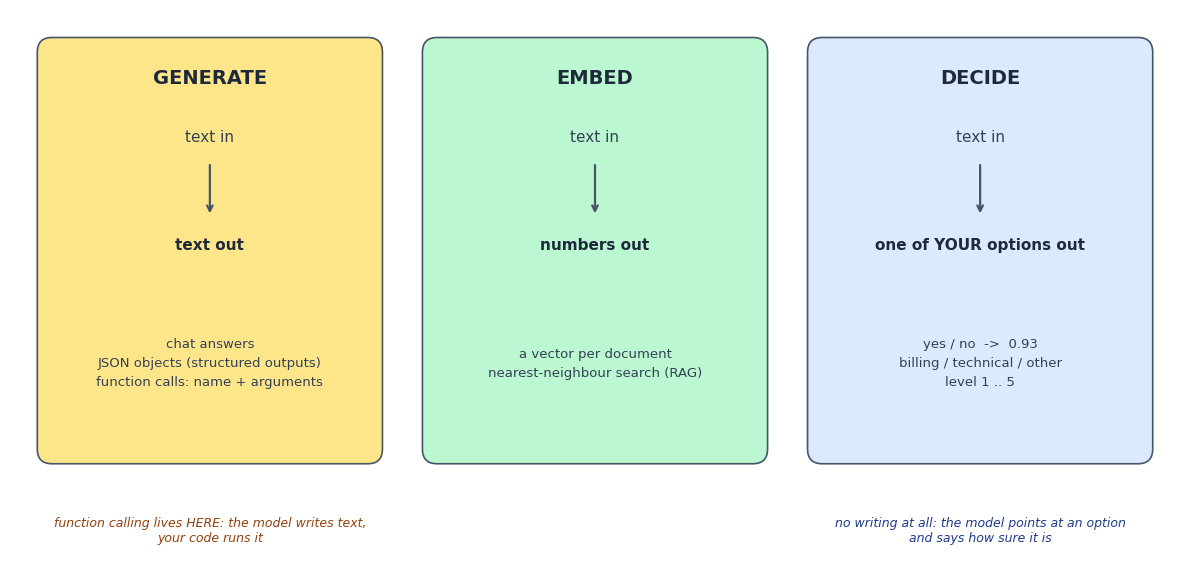

In [1]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

os.makedirs("images", exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5.8))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.6); ax.axis("off")

columns = [  # (x, title, color, what goes in, what comes out, examples)
    (0.3, "GENERATE", "#fde68a", "text in", "text out",
     "chat answers\nJSON objects (structured outputs)\nfunction calls: name + arguments"),
    (4.25, "EMBED", "#bbf7d0", "text in", "numbers out",
     "a vector per document\nnearest-neighbour search (RAG)"),
    (8.2, "DECIDE", "#dbeafe", "text in", "one of YOUR options out",
     "yes / no  ->  0.93\nbilling / technical / other\nlevel 1 .. 5"),
]
for x, title, color, inp, out, examples in columns:
    ax.add_patch(FancyBboxPatch((x, 1.0), 3.5, 4.3, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor=color, edgecolor="#475569", linewidth=1.2))
    ax.text(x + 1.75, 4.9, title, ha="center", va="center", fontsize=14, fontweight="bold", color="#1e293b")
    ax.text(x + 1.75, 4.3, inp, ha="center", va="center", fontsize=11, color="#334155")
    ax.annotate("", xy=(x + 1.75, 3.5), xytext=(x + 1.75, 4.05),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="#475569"))
    ax.text(x + 1.75, 3.2, out, ha="center", va="center", fontsize=11, fontweight="bold", color="#1e293b")
    ax.text(x + 1.75, 2.0, examples, ha="center", va="center", fontsize=9.5, color="#334155", linespacing=1.6)

ax.text(2.05, 0.15, "function calling lives HERE: the model writes text,\nyour code runs it",
        ha="center", va="bottom", fontsize=9, style="italic", color="#92400e")
ax.text(9.95, 0.15, "no writing at all: the model points at an option\nand says how sure it is",
        ha="center", va="bottom", fontsize=9, style="italic", color="#1e3a8a")

plt.tight_layout()
plt.savefig("images/three_primitives.png", dpi=150, bbox_inches="tight")
plt.show()

Keep this picture. *Decide* is the small, cheap box on the right. It is not smarter than *generate*; it answers a much narrower question, and that is exactly why it is fast. The rest of the notebook is about finding the narrow questions hiding inside your app.

## Setup

Same setup cell as always, with one change: `MODEL = "gpt-6-luna"`, because the Decisions API currently runs only on this model. It is the small model of the newest generation, cheaper than the one we used so far. The `openai` package must be version 3.26 or newer for `client.decisions` to exist.

In [2]:
%pip install -q openai==3.35.1 matplotlib   # Colab installs here; locally, `pip install -r requirements.txt` already covers it

import os
from openai import OpenAI

# Your key, looked up in this order: Colab secret -> environment variable -> a prompt.
try:
    from google.colab import userdata
    api_key = userdata.get("OPENAI_API_KEY")
except Exception:
    api_key = os.environ.get("OPENAI_API_KEY")
if not api_key:
    from getpass import getpass
    api_key = getpass("OpenAI API key: ")

client = OpenAI(api_key=api_key.strip())
MODEL = "gpt-6-luna"   # the Decisions API runs only on this model today; on Responses it costs 0.10 USD in / 0.50 USD out per 1M tokens

import json, time, statistics
print("Ready. Model:", MODEL)

Note: you may need to restart the kernel to use updated packages.
Ready. Model: gpt-6-luna


## The running story: a support inbox

We are the one-person support desk of a small online shop. Messages arrive all day. For each one we want to know, fast: does it need an answer right now, who should handle it, how upset is the person. Nobody needs an essay for that; a tick in the right box is enough.

Here are eight messages from this morning. We will keep coming back to them.

In [3]:
messages = [
    "Hi, my order 4471 arrived with a cracked screen. I want my money back today or I'm posting this everywhere!!!",
    "Hello, could you tell me whether the blue version of the kids' bike will be back in stock before Christmas?",
    "The app keeps logging me out every few minutes since yesterday's update. iPhone 15, latest iOS.",
    "Invoice 2026-0912 shows my old address. Can you reissue it? No rush.",
    "I was charged twice for order 4502. Please refund the second payment, 89.90 EUR.",
    "Thanks for the quick delivery last week, the helmet fits perfectly. Just wanted to say that.",
    "Is the blue version coming back? Also my last invoice has the wrong company name on it, we can't book it.",
    "URGENT: my daughter's birthday is tomorrow and the tracking says the parcel is stuck in Vienna since Friday. Order 4490.",
]
print(len(messages), "messages in the inbox")

8 messages in the inbox


## The first decision: a yes/no question

We want to know whether a message needs an answer within the hour. Ask it as a **predicate**: a yes/no question that the model answers with a probability.

Same `client`, new endpoint: `client.decisions.create`. You hand over the text and a list of questions. Every question has a `type`, a `name` (so you can find its answer later) and `instructions` written in plain words. Let's ask about the two most different messages in the inbox: the stuck birthday parcel and the thank-you note.

In [4]:
for text in [messages[7], messages[5]]:
    decision = client.decisions.create(
        model=MODEL,
        input=text,
        questions=[
            {"type": "predicate", "name": "urgent",
             "instructions": "Does the customer need a reply within the hour?"},
        ],
    )
    answer = decision.answers[0]
    print(f"{text[:70]}...")
    print(f"   urgent? probability {answer.probability:.2f}   (output tokens: {decision.usage.output_tokens})\n")

URGENT: my daughter's birthday is tomorrow and the tracking says the p...
   urgent? probability 0.82   (output tokens: 0)

Thanks for the quick delivery last week, the helmet fits perfectly. Ju...
   urgent? probability 0.05   (output tokens: 0)



### 🔍 What just happened?

No text came back. `output_tokens` is 0: the model generated nothing. It read the message and your question and returned one number, the probability that the answer is yes. That number is the whole product.

**Decode of the key line:** `client.decisions.create(model=..., input=..., questions=[...])` has the same shape as the `responses.create` call you know, only `questions=` replaces the free-form prompt. You are not asking the model to talk; you are asking it to fill in a form you designed. The `name` is the label on the form field, the `instructions` are the question printed next to it.

## Three kinds of questions

Yes/no is one kind of form field. There are two more:

- **choice**: one option out of a list you wrote. *Which team should handle this?*
- **score**: a level on an ordered scale. *How upset is the customer?*

Every option and every level can carry a `description` that says when it applies. Write these the way you would explain the categories to a new colleague on their first morning, because the model reads nothing else about your shop. Several questions can travel in one request; let's send all three for the angry first message.

In [5]:
questions = [
    {"type": "predicate", "name": "urgent",
     "instructions": "Does the customer need a reply within the hour?"},
    {"type": "choice", "name": "team",
     "instructions": "Which team should handle this message?",
     "choices": [
         {"value": "billing",   "description": "refunds, double charges, invoices, payments"},
         {"value": "technical", "description": "broken products, app or website problems"},
         {"value": "other",     "description": "stock questions, delivery status, feedback, anything else"},
     ]},
    {"type": "score", "name": "mood",
     "instructions": "How upset is the customer?",
     "levels": [
         {"label": "calm",    "description": "polite or neutral, no pressure"},
         {"label": "annoyed", "description": "frustrated but civil"},
         {"label": "furious", "description": "threats, shouting, ultimatums"},
     ]},
]

decision = client.decisions.create(model=MODEL, input=messages[0], questions=questions)

print(messages[0], "\n")
for answer in decision.answers:
    if answer.type == "predicate":
        print(f"{answer.name:<8} probability {answer.probability:.2f}")
    elif answer.type == "choice":
        spread = ", ".join(f"{p.value} {p.probability:.2f}" for p in answer.probabilities)
        print(f"{answer.name:<8} {answer.choice}   (confidence {answer.confidence:.2f};  {spread})")
    elif answer.type == "score":
        spread = ", ".join(f"{p.label} {p.probability:.2f}" for p in answer.probabilities)
        print(f"{answer.name:<8} score {answer.score:.2f} on 0..{len(answer.probabilities) - 1}   ({spread})")
print("\ntokens:", decision.usage.input_tokens, "in,", decision.usage.output_tokens, "out")

Hi, my order 4471 arrived with a cracked screen. I want my money back today or I'm posting this everywhere!!! 

urgent   probability 0.24
team     technical   (confidence 0.74;  billing 0.17, technical 0.83, other 0.00)
mood     score 1.98 on 0..2   (calm 0.00, annoyed 0.02, furious 0.98)

tokens: 445 in, 0 out


### 🔍 What just happened?

Three answers in one round trip, each tagged with the `name` you gave it. The choice answer carries three things: the `choice` itself, a probability for *every* option, and a separate `confidence`. The score answer is a weighted average of the level numbers (0 for calm, 2 for furious), so a score near 2 means "furious, and sure about it".

Notice what did *not* happen: the model could not invent a fourth team or a level called "hangry". That is the safety and the limit of this endpoint in one sentence. It cannot answer outside your list, and it cannot tell you that your list is wrong.

One more thing to notice: `urgent` came back low although the customer wrote "today". The model read the ultimatum as anger, not as a deadline. Whether you agree or not, the lesson is that the *wording of the question* decides the answer. "Needs a reply within the hour" asks for a judgement; "mentions a deadline" asks about a fact in the text. Questions about facts in the text get the reliable answers. Keep that in mind when you write your own.

### 🎯 Mini-task

Add a fourth question to `questions`: a predicate named `has_order_number`, "Does the customer mention an order number?". Run it on `messages[3]` (an invoice number, not an order) and `messages[4]`. Does the model tell the two apart?

## Where the probabilities matter: act, hold, escalate

A classifier that only says "billing" is useful. One that says "billing, 0.89" is useful in a new way: you can set a **threshold**. Above it, route the message automatically. Below it, put it in a human's queue.

Let's wrap the call in a small helper that returns the answers by name, run all eight messages through it, and apply one rule: confidence of at least 0.85 means auto-route, anything lower is held for a person.

In [6]:
def decide(text, questions):
    """Ask the decision model; return {name: answer} so the caller can look answers up by name."""
    decision = client.decisions.create(model=MODEL, input=text, questions=questions)
    return {answer.name: answer for answer in decision.answers}


THRESHOLD = 0.85
latencies = []

print(f"{'#':<3}{'team':<11}{'conf':<7}{'mood':<6}{'urgent':<8}{'action':<8}message")
for i, text in enumerate(messages):
    started = time.time()
    answers = decide(text, questions)
    latencies.append(time.time() - started)
    team, mood, urgent = answers["team"], answers["mood"], answers["urgent"]
    action = "auto" if team.confidence >= THRESHOLD else "HOLD"
    print(f"{i:<3}{team.choice:<11}{team.confidence:<7.2f}{mood.score:<6.2f}{urgent.probability:<8.2f}{action:<8}{text[:48]}...")

print(f"\nmedian time per decision: {statistics.median(latencies):.2f} s  (three questions each)")

#  team       conf   mood  urgent  action  message
0  technical  0.74   1.98  0.24    HOLD    Hi, my order 4471 arrived with a cracked screen....
1  other      1.00   0.01  0.01    auto    Hello, could you tell me whether the blue versio...
2  technical  1.00   0.98  0.22    auto    The app keeps logging me out every few minutes s...
3  billing    1.00   0.00  0.00    auto    Invoice 2026-0912 shows my old address. Can you ...
4  billing    1.00   0.01  0.05    auto    I was charged twice for order 4502. Please refun...
5  other      0.97   0.00  0.05    auto    Thanks for the quick delivery last week, the hel...
6  billing    0.64   0.51  0.14    HOLD    Is the blue version coming back? Also my last in...
7  other      1.00   0.99  0.82    auto    URGENT: my daughter's birthday is tomorrow and t...

median time per decision: 0.28 s  (three questions each)


### 🔍 What just happened?

The rows marked HOLD are the point of this section. Message 6 is a stock question *and* an invoice problem in one breath. Message 0 is a broken product (technical) with a money-back demand (billing). In both cases the model did not refuse and did not make anything up; it picked a valid team with low confidence, and the rule caught it. Without the probability you would have routed each one somewhere and never known it was a coin toss.

This is also the honest limit. A confident wrong answer looks exactly like a confident right answer. The vendors call these models "immune to hallucination" because they cannot invent an option; they can still pick the wrong one. Before you trust a threshold in production, run a few dozen messages you have labelled by hand and see where the mistakes sit.

## Decide first, then act: pairing with function calling

Back to the agent from the function-calling chapter. There the model chose the tool *and* wrote its arguments in one generative step. We can split that in two. The decision model picks the tool, fast and with a probability. Then the ordinary model fills in the arguments, with `tool_choice` forcing exactly that function.

Two tools for our shop: `lookup_order(order_id)` and `issue_refund(order_id, amount)`. And one more option in the list, `none`, because most messages need no tool at all.

In [7]:
def lookup_order(order_id: str) -> dict:
    """Mock: where is this order? In a real shop this queries the carrier."""
    return {"order_id": order_id, "status": "in transit", "last_scan": "Vienna hub, Friday 18:40"}


def issue_refund(order_id: str, amount: float) -> dict:
    """Mock: refund money. In a real shop this talks to the payment provider."""
    return {"order_id": order_id, "refunded": amount, "currency": "EUR"}


functions = {"lookup_order": lookup_order, "issue_refund": issue_refund}

tools = [
    {"type": "function", "name": "lookup_order", "strict": True,
     "description": "Look up the delivery status of an order.",
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string"}},
                    "required": ["order_id"], "additionalProperties": False}},
    {"type": "function", "name": "issue_refund", "strict": True,
     "description": "Refund an amount for an order.",
     "parameters": {"type": "object",
                    "properties": {"order_id": {"type": "string"}, "amount": {"type": "number", "description": "in EUR"}},
                    "required": ["order_id", "amount"], "additionalProperties": False}},
]

tool_question = {
    "type": "choice", "name": "tool", "instructions": "Which tool, if any, does this message call for?",
    "choices": [
        {"value": "lookup_order",  "description": "the customer asks where a specific order is or what its status is"},
        {"value": "issue_refund",  "description": "the customer explicitly asks for money back and names an order"},
        {"value": "none",          "description": "no tool needed: questions, feedback, anything the two tools cannot do"},
    ],
}


def handle(text):
    # Step 1: the decision model picks the tool (cheap, with a probability).
    picked = decide(text, [tool_question])["tool"]
    print(f"decision: {picked.choice} (confidence {picked.confidence:.2f})")
    if picked.choice == "none":
        return
    # Step 2: the ordinary model only has to write the arguments for that one tool.
    response = client.responses.create(
        model=MODEL, input=text, tools=tools,
        tool_choice={"type": "function", "name": picked.choice},    # forced: no choosing left to do
    )
    call = next(item for item in response.output if item.type == "function_call")
    args = json.loads(call.arguments)
    print(f"arguments: {args}")
    print(f"result:    {functions[call.name](**args)}")


for text in [messages[7], messages[4], messages[5]]:
    print(text[:70] + "...")
    handle(text)
    print()

URGENT: my daughter's birthday is tomorrow and the tracking says the p...
decision: lookup_order (confidence 0.99)
arguments: {'order_id': '4490'}
result:    {'order_id': '4490', 'status': 'in transit', 'last_scan': 'Vienna hub, Friday 18:40'}

I was charged twice for order 4502. Please refund the second payment, ...
decision: issue_refund (confidence 1.00)
arguments: {'order_id': '4502', 'amount': 89.9}
result:    {'order_id': '4502', 'refunded': 89.9, 'currency': 'EUR'}

Thanks for the quick delivery last week, the helmet fits perfectly. Ju...
decision: none (confidence 1.00)



### 🔍 What just happened?

The decision step chose; the generation step only ran when needed, and then it only had to write arguments, with no choosing left to do. Why bother splitting? Three reasons.

- The choice is cheap enough to run on every message, so it can also act as a filter in front of the expensive model.
- The probability gives you a place for a threshold: refunds picked with confidence below 0.9 go to a human first.
- A model that can only choose from your list cannot be talked into calling a tool you did not offer, whatever the message says.

In real agent loops this is where decision models are landing: as the small gate next to the big model, not as its replacement. The big model still writes, reasons and calls tools. The small one answers the many yes/no and which-one questions around it.

## Checking the model's own work: the gate on the way out

The second place for a gate is *after* generation. The model drafts a reply to a customer; before it goes out, a predicate checks it against our policy: never promise a refund, a discount or a delivery date in writing. Drafts that pass are sent, the rest wait for a person. The judge is cheap, so you can afford to run it on every single reply.

To see the gate catch something, the third draft below is written by hand, the way an over-eager new colleague might write it.

In [8]:
drafting_instructions = ("You are the support assistant of a small online shop. Reply in two short, warm sentences. "
                         "Policy: never promise a refund, a discount or a delivery date; say the team will look into it today.")

drafts = []
for text in [messages[0], messages[7]]:
    response = client.responses.create(
        model=MODEL,
        input=[{"role": "developer", "content": drafting_instructions}, {"role": "user", "content": text}],
    )
    drafts.append(response.output_text)
drafts.append("So sorry about that! I've refunded you in full and a replacement will be with you by Thursday, "
              "plus a 20% voucher for the trouble.")

policy_check = {"type": "predicate", "name": "breaks_policy",
                "instructions": "Does the draft promise a refund, a discount, or a specific delivery date?"}

for draft in drafts:
    verdict = decide(f"Draft reply to a customer:\n{draft}", [policy_check])["breaks_policy"]
    status = "HOLD for review" if verdict.probability >= 0.5 else "send"
    print(f"[{status:<15}] p(breaks policy) = {verdict.probability:.2f}\n   {draft}\n")

[send           ] p(breaks policy) = 0.00
   I’m so sorry order 4471 arrived with a cracked screen—that’s understandably frustrating. Our team will look into this today and follow up with you about the next steps.

[send           ] p(breaks policy) = 0.00
   I’m sorry the parcel is delayed, especially with your daughter’s birthday tomorrow. We’ll ask the team to look into order 4490 and its tracking in Vienna today.

[HOLD for review] p(breaks policy) = 1.00
   So sorry about that! I've refunded you in full and a replacement will be with you by Thursday, plus a 20% voucher for the trouble.



### 🔍 What just happened?

Two generated drafts passed, the hand-written one was held. The judge never saw the customer's message, only the draft and the question, and that is enough: "does this text promise X?" is an observable fact about the text, which is the kind of question these models are good at.

You met this idea in disguise before: people call it an **LLM-as-judge**. The novelty is the price. A judge that costs a full model call runs on a sample of replies; a judge that costs a hundredth of a cent and a quarter of a second runs on all of them.

## The bill: speed and price

Now the claim from the headlines. Same question, same model, two doors: `responses.parse` with a structured output (the way you would have solved this last chapter) and `decisions.create`. We route all eight messages through each door twice, time every call and count tokens.

Prices today, per million tokens: gpt-6-luna on Responses costs 0.10 USD for input and 0.50 USD for output; on Decisions it costs 0.10 USD for input and nothing for output, because there is none. Check the [pricing page](https://developers.openai.com/api/docs/pricing) before you quote these; they change.

In [9]:
from pydantic import BaseModel
from typing import Literal


class Route(BaseModel):
    team: Literal["billing", "technical", "other"]


routing_prompt = ("Which team should handle this message? billing: refunds, double charges, invoices, payments. "
                  "technical: broken products, app or website problems. other: stock questions, delivery status, feedback, anything else.")
team_question = questions[1]          # the same choice question as before


def via_responses(text):
    response = client.responses.parse(
        model=MODEL, text_format=Route,
        input=[{"role": "developer", "content": routing_prompt}, {"role": "user", "content": text}],
    )
    return response.output_parsed.team, response.usage.input_tokens, response.usage.output_tokens


def via_decisions(text):
    decision = client.decisions.create(model=MODEL, input=text, questions=[team_question])
    return decision.answers[0].choice, decision.usage.input_tokens, decision.usage.output_tokens


PRICE = {"responses": (0.10, 0.50), "decisions": (0.10, 0.00)}     # USD per 1M tokens: (input, output)
ROUNDS = 2                                                           # every message twice, so one slow call cannot skew the median
results = {}
for door, fn in [("responses", via_responses), ("decisions", via_decisions)]:
    fn(messages[0])                                                  # warm-up call, not timed
    times, teams, tokens_in, tokens_out = [], [], 0, 0
    for _ in range(ROUNDS):
        for text in messages:
            started = time.time()
            team, n_in, n_out = fn(text)
            times.append(time.time() - started)
            teams.append(team); tokens_in += n_in; tokens_out += n_out
    cost = (tokens_in * PRICE[door][0] + tokens_out * PRICE[door][1]) / 1_000_000
    results[door] = {"median_s": statistics.median(times), "in": tokens_in, "out": tokens_out, "cost": cost, "teams": teams}

n_calls = ROUNDS * len(messages)
print(f"{'door':<11}{'median s':<10}{'tokens in':<11}{'tokens out':<12}{'cost, 16 calls':<16}cost per 100,000 msgs")
for door, r in results.items():
    print(f"{door:<11}{r['median_s']:<10.2f}{r['in']:<11}{r['out']:<12}{r['cost']:<16.5f}{r['cost'] / n_calls * 100_000:.2f} USD")

differ = sorted({i % len(messages) for i, (a, b) in enumerate(zip(results["responses"]["teams"], results["decisions"]["teams"])) if a != b})
print(f"\nmessages where the two doors picked different teams: {differ if differ else 'none'}")

door       median s  tokens in  tokens out  cost, 16 calls  cost per 100,000 msgs
responses  1.25      1790       489         0.00042         2.65 USD
decisions  0.24      2606       0           0.00026         1.63 USD

messages where the two doors picked different teams: [0]


### 🔍 What just happened?

Two columns matter. **Price** is deterministic: the decisions door is cheaper even though it read *more* input tokens (the option descriptions cost tokens too), because it writes nothing, while the responses door thinks before it writes JSON and those reasoning tokens are billed as output. **Speed** is not deterministic: OpenAI quotes "about 10x faster"; on our runs we saw anything from a quarter of a second to, during one busy afternoon of the beta, slower than the responses door. Measure in your own setting before you promise a latency to anyone.

The last line tells you whether the cheaper door would have changed any routing. When the doors disagree it is on the ambiguous messages, the ones the HOLD rule already flags.

Vendors' comparison charts are built on exactly this kind of match-up, a model forced to write against a model that only points, so read their "40x cheaper" claims with that in mind. Even so, the direction is clear and it holds at every scale. At under two cents per thousand decisions you can afford one on every message, every tool call and every reply, which is the whole reason this category exists.

## What else exists

One sentence each, so you recognise the names when you meet them:

- **Images.** The Decisions API also takes pictures (inline base64 only): "is this returned product damaged?" as a predicate. The [guide](https://developers.openai.com/api/docs/guides/decisions) has the example.
- **Writing good questions.** OpenAI's own advice: ask about observable facts, one concern per question, give every option a distinct meaning, always include an `other`, and set thresholds on a few dozen labelled examples from your app.
- **Microsoft-Decision-1.** The same three shapes (yes/no, choice, score) as a separately trained model, available in Microsoft Foundry and on OpenRouter.
- **Jev** by TypeSafe AI, the model that started the category in September 2026. API only, closed weights.
- **Open weights.** Cloudflare's Clef and AWS's Strands Decider are decision models you can run on your own machine, the way the next chapter runs open models.
- **Status.** The Decisions API was in public beta in October 2026 and the category was a few weeks old. The vendor names will change; the primitive, a bounded question with a calibrated answer, will stay.

## 🎯 Your turn

Build a comment gate for the product-review section of the shop. Write six short customer comments: a few honest reviews, one with a phone number in it, one that is only an insult, one that is spam for another website. Ask one `choice` question with the options `publish`, `review` and `block`, each with a description. Apply two rules: auto-publish only when the choice is `publish` with confidence of at least 0.9; everything else goes to the review queue, except that `block` with any confidence is blocked. Print a table.

If that was easy: add a `score` question "how useful is this review for other shoppers?" with three levels and sort the published comments by it.